# Robotics — Assignment 1: Motor Identification

Step tests and square-wave validation for motors M3 and M4.

## Motor model

- **θ**: shaft angle (rad); **ω**: angular speed (rad/s); **U**: applied voltage (V), approximated as `(PWM/100) × U_battery`.
- **ωss**: final speed under constant PWM (rad/s); **Tm**: time to reach 63.2% of ωss (s); **ke**: back-EMF constant (V·s/rad).

\[\frac{d\omega}{dt}=\frac{U}{T_m k_e}-\frac{\omega}{T_m},\qquad \frac{d\theta}{dt}=\omega\]

For a voltage step from rest, solving the linear ODE gives \(\omega(t)=\omega_{ss}(1-e^{-t/T_m})\). Integrating once more:

\[\boxed{\theta(t)=\omega_{ss}\,[t-T_m+T_m e^{-t/T_m}]},\qquad \omega_{ss}=U/k_e\]

**Assumptions:** negligible inductance, linear viscous friction, constant load and constant battery voltage during each run.

## Measurements

Encoder angle (degrees), time (ms), PWM (%). Battery estimates: M3 = 11.4 V; M4 = 11.3 V. In Google Colab, run the first cell and upload `assignment_1_data.zip` when prompted.

In [1]:
from pathlib import Path
from zipfile import ZipFile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize
from scipy.integrate import odeint
from IPython.display import display

DATA = Path('motor_data')
if not (DATA / 'steps_M3_run1.txt').exists():
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError('Extract assignment_1_data.zip beside the notebook')
    uploaded = files.upload()
    with ZipFile(next(iter(uploaded))) as archive:
        archive.extractall('.')
assert (DATA / 'steps_M3_run1.txt').exists(), 'Missing motor_data files'

FIGS = Path('figures')
FIGS.mkdir(exist_ok=True)
BATTERY = {'M3': 11.4, 'M4': 11.3}
MOTORS = ('M3', 'M4')
RUNS = (1, 2)
plt.rcParams.update({'figure.figsize': (10, 5), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10, 'savefig.dpi': 150})

def load(f):
    a = np.loadtxt(DATA / f, delimiter=',')
    assert a.ndim == 2 and a.shape[1] == 3 and len(a) > 10 and np.all(np.diff(a[:, 1]) > 0), f
    return a

def segments(a):
    cuts = np.r_[0, np.flatnonzero(np.diff(a[:, 2]) != 0) + 1, len(a)]
    return [(a[s:e], int(round(a[s, 2])), s, e) for s, e in zip(cuts[:-1], cuts[1:])]

raw_step = {(m, r): load(f'steps_{m}_run{r}.txt') for m in MOTORS for r in RUNS}
raw_signal = {m: load(f'signal_{m}_square_run1.txt') for m in MOTORS}
print('Step runs:', len(raw_step), '| Square-wave runs:', len(raw_signal))

Step runs: 4 | Square-wave runs: 2


## Step-response fitting

Estimate steady-state speed and time constant at every PWM using the first-order step model.

In [2]:
def step_angle(t, w_ss, T_m):
    return w_ss * (t - T_m + T_m * np.exp(-t/T_m))

records=[]; step_curves={}
for m in MOTORS:
    for run in RUNS:
        a=raw_step[m,run]
        pset=[]
        for z,p,start,end in segments(a):
            if p==0:continue
            t=(z[:,1]-z[0,1])/1000.0
            theta=np.deg2rad(z[:,0]-z[0,0])
            fitted,cov=optimize.curve_fit(step_angle,t,theta,p0=[np.sign(p)*10,0.15],
                    bounds=([-40,0.01],[40,1.5]),maxfev=20000)
            err=np.sqrt(np.maximum(np.diag(cov),0))
            records.append({'Motor':m,'Run':run,'PWM':p,'omega_ss':fitted[0],
                            'Tm':fitted[1],'SE_omega':err[0],'SE_Tm':err[1],
                            'RMS_step':np.sqrt(np.mean((theta-step_angle(t,*fitted))**2))})
            step_curves[m,run,p]=(t,theta,*fitted)
fit_rows=pd.DataFrame.from_records(records).sort_values(['Motor','PWM','Run']).reset_index(drop=True)
assert len(fit_rows)==80
print(f'Fitted {len(fit_rows)} individual step responses; full table saved to results/all_80_step_fits.csv.')

Fitted 80 individual step responses; full table saved to results/all_80_step_fits.csv.


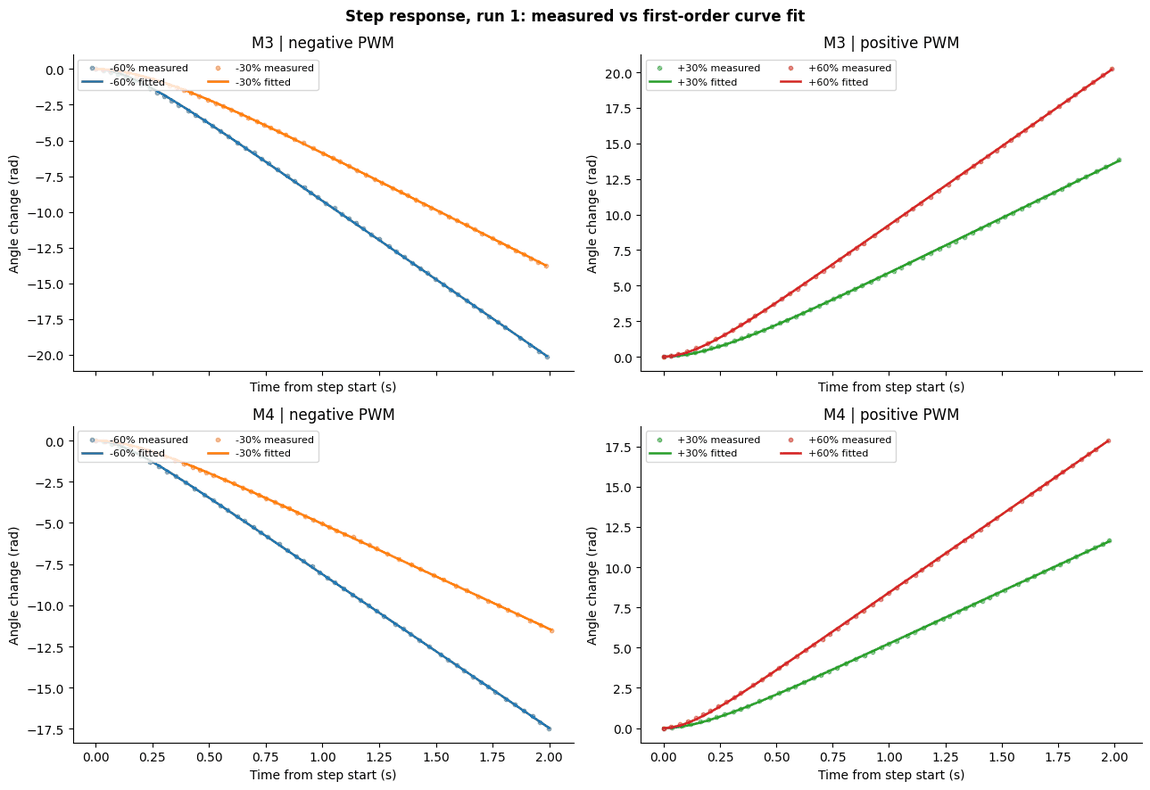

In [3]:
fig,axes=plt.subplots(2,2,figsize=(13,9),sharex='col')
for j,m in enumerate(MOTORS):
    for i,p in enumerate((-60,-30,30,60)):
        ax=axes[j,i//2]
        t,th,ws,Tm=step_curves[m,1,p]
        c=plt.get_cmap('tab10')(i)
        ax.scatter(t,th,s=10,color=c,alpha=.50,label=f'{p:+d}% measured')
        ax.plot(t,step_angle(t,ws,Tm),color=c,linewidth=1.9,label=f'{p:+d}% fitted')
        ax.set_xlabel('Time from step start (s)'); ax.set_ylabel('Angle change (rad)')
        ax.set_title(f'{m} | '+('negative PWM' if i<2 else 'positive PWM'))
        ax.legend(fontsize=8,ncol=2,loc='upper left')
fig.suptitle('Step response, run 1: measured vs first-order curve fit',fontweight='bold')
fig.tight_layout();fig.savefig(FIGS/'01_step_response_fits.png');plt.show()

## Speed and time constant vs PWM

In [4]:
agg=fit_rows.groupby(['Motor','PWM']).agg(
    omega_ss=('omega_ss','mean'),Tm=('Tm','mean'),
    SE_omega=('SE_omega',lambda a:np.sqrt(np.sum(a*a))/len(a)),
    SE_Tm=('SE_Tm',lambda a:np.sqrt(np.sum(a*a))/len(a)),
    omega_run_spread=('omega_ss',lambda a:float(np.ptp(a))),
    Tm_run_spread=('Tm',lambda a:float(np.ptp(a)))).reset_index()

calibration={};summary=[]
for m in MOTORS:
    for direction in ['Backward','Forward']:
        q=agg[(agg.Motor==m)&(agg.PWM.between(-90,-30) if direction=='Backward' else agg.PWM.between(30,90))]
        pwm=q.PWM.to_numpy(dtype=float); w=q.omega_ss.to_numpy()
        slope,intercept=np.polyfit(pwm,w,1)
        slope0=np.dot(pwm,w)/np.dot(pwm,pwm)
        ke=BATTERY[m]/(100*abs(slope))
        ke0=BATTERY[m]/(100*abs(slope0))
        calibration[m,direction]={'slope':slope,'intercept':intercept,'ke':ke,
                                  'slope_origin':slope0,'ke_origin':ke0,'Tm':float(q.Tm.mean())}
        summary.append({'Motor':m,'Direction':direction,'Dead zone (% PWM)':'unresolved (<10)',
                        'Slope (rad/s/%)':slope,'Intercept (rad/s)':intercept,
                        'ke slope (V s/rad)':ke,'ke through-origin (V s/rad)':ke0,
                        'Mean Tm (s), |PWM| 30-90':q.Tm.mean(),'Battery estimate (V)':BATTERY[m]})
summary=pd.DataFrame(summary)
display(summary[['Motor','Direction','ke slope (V s/rad)','Mean Tm (s), |PWM| 30-90']].round(3).reset_index(drop=True))

  Motor Direction  ke slope (V s/rad)  Mean Tm (s), |PWM| 30-90
0    M3  Backward               1.231                     0.162
1    M3   Forward               1.124                     0.155
2    M4  Backward               1.118                     0.126
3    M4   Forward               1.032                     0.121

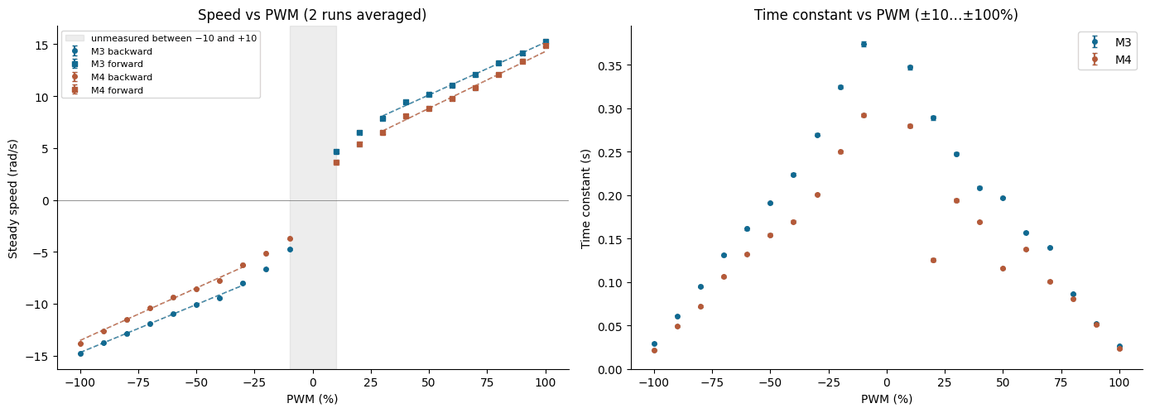

In [5]:
fig,axs=plt.subplots(1,2,figsize=(14,5.1))
cc={'M3':'#136b92','M4':'#b45a39'}
for m in MOTORS:
    q=agg[agg.Motor==m]
    for sign,fmt in [(-1,'o'),(1,'s')]:
        dq=q[np.sign(q.PWM)==sign]
        axs[0].errorbar(dq.PWM,dq.omega_ss,yerr=dq.SE_omega,color=cc[m],fmt=fmt,
                 capsize=2,label=f'{m} '+('backward' if sign<0 else 'forward'),markersize=4)
        c=calibration[m,'Forward' if sign>0 else 'Backward']
        xx=np.linspace(dq.PWM.min() if sign<0 else 30,-30 if sign<0 else dq.PWM.max(),100)
        axs[0].plot(xx,c['slope']*xx+c['intercept'],color=cc[m],linestyle='--',lw=1.2,alpha=.8)
axs[0].axvspan(-10,10,color='gray',alpha=.14,label='unmeasured between −10 and +10')
axs[0].set(xlabel='PWM (%)',ylabel='Steady speed (rad/s)',title='Speed vs PWM (2 runs averaged)')
axs[0].axhline(0,color='gray',lw=.6);axs[0].legend(fontsize=8,loc='upper left')
for m in MOTORS:
    q=agg[agg.Motor==m]
    axs[1].errorbar(q.PWM,q.Tm,yerr=q.SE_Tm,color=cc[m],fmt='o',markersize=4,capsize=2,label=m)
axs[1].set(xlabel='PWM (%)',ylabel='Time constant (s)',title='Time constant vs PWM (±10…±100%)')
axs[1].legend();axs[1].set_ylim(bottom=0);fig.tight_layout()
fig.savefig(FIGS/'02_speed_and_timeconstant_vs_pwm.png');plt.show()

## Square-wave validation

Compare measured and predicted motor angles and speeds for ±60% PWM.

In [6]:
def smooth(x,n=5):
    return pd.Series(np.asarray(x)).rolling(window=n,center=True,min_periods=1).mean().to_numpy()

def simulate(m,t,pwm,method='constant',initial_w=0.0):
    q=agg[agg.Motor==m]
    reg=q[q.PWM.abs().between(30,90)]
    x=reg.PWM.to_numpy(dtype=float); v=reg.omega_ss.to_numpy()
    gain=float(np.dot(x,v)/np.dot(x,x))
    ke_effective=BATTERY[m]/(100*abs(gain))
    tm=float(reg.Tm.median())
    pos=q[q.PWM==60].iloc[0];neg=q[q.PWM==-60].iloc[0]
    def motor(y,ti):
        omega,angle=y
        u=float(np.interp(ti,t,pwm))
        voltage=(u/100)*BATTERY[m]
        if method=='constant':
            target=voltage/ke_effective
            tau=tm
        elif method=='deadzone5':
            u_eff=np.sign(u)*max(abs(u)-5,0)
            target=(BATTERY[m]*u_eff/100)/ke_effective
            tau=tm
        elif method=='directional60':
            ke_dir=(BATTERY[m]*.60)/float(pos.omega_ss) if u>=0 else (-BATTERY[m]*.60)/float(neg.omega_ss)
            target=voltage/ke_dir
            tau=float(pos.Tm if u>=0 else neg.Tm)
        else:
            raise ValueError(method)
        return np.array([(target-omega)/tau,omega])
    return odeint(motor,[initial_w,0.0],t,rtol=1e-8,atol=1e-9)

def fitpct(measured,pred):
    denom=np.linalg.norm(measured-np.mean(measured))
    return 100*(1-np.linalg.norm(measured-pred)/denom) if denom>1e-12 else np.nan

sq_data={}; sq_metric=[]
for m in MOTORS:
    a=raw_signal[m]
    t=(a[:,1]-a[0,1])/1000
    th=np.deg2rad(a[:,0]-a[0,0]);pwm=a[:,2]
    omega_smooth=smooth(np.gradient(th,t),5)
    methods={k:simulate(m,t,pwm,k) for k in ('constant','deadzone5','directional60')}
    sq_data[m]={'time':t,'angle':th,'PWM':pwm,'omega_smooth':omega_smooth,'prediction':methods}
    for name,pred in methods.items():
        pomega=smooth(pred[:,0],5)
        sq_metric.append({'Motor':m,'Model':name,'Angle RMSE (rad)':np.sqrt(np.mean((th-pred[:,1])**2)),
                          'Angle fit (%)':fitpct(th,pred[:,1]),
                          'Speed RMSE (rad/s)':np.sqrt(np.mean((omega_smooth-pomega)**2)),
                          'Speed fit (%)':fitpct(omega_smooth,pomega)})
metrics=pd.DataFrame(sq_metric)
display(metrics.round(3))

  Motor          Model  ...  Speed RMSE (rad/s)  Speed fit (%)
0    M3       constant  ...               0.835         84.815
1    M3      deadzone5  ...               0.940         82.910
2    M3  directional60  ...               0.881         83.969
3    M4       constant  ...               0.704         86.308
4    M4      deadzone5  ...               0.688         86.616
5    M4  directional60  ...               0.597         88.390

[6 rows x 6 columns]

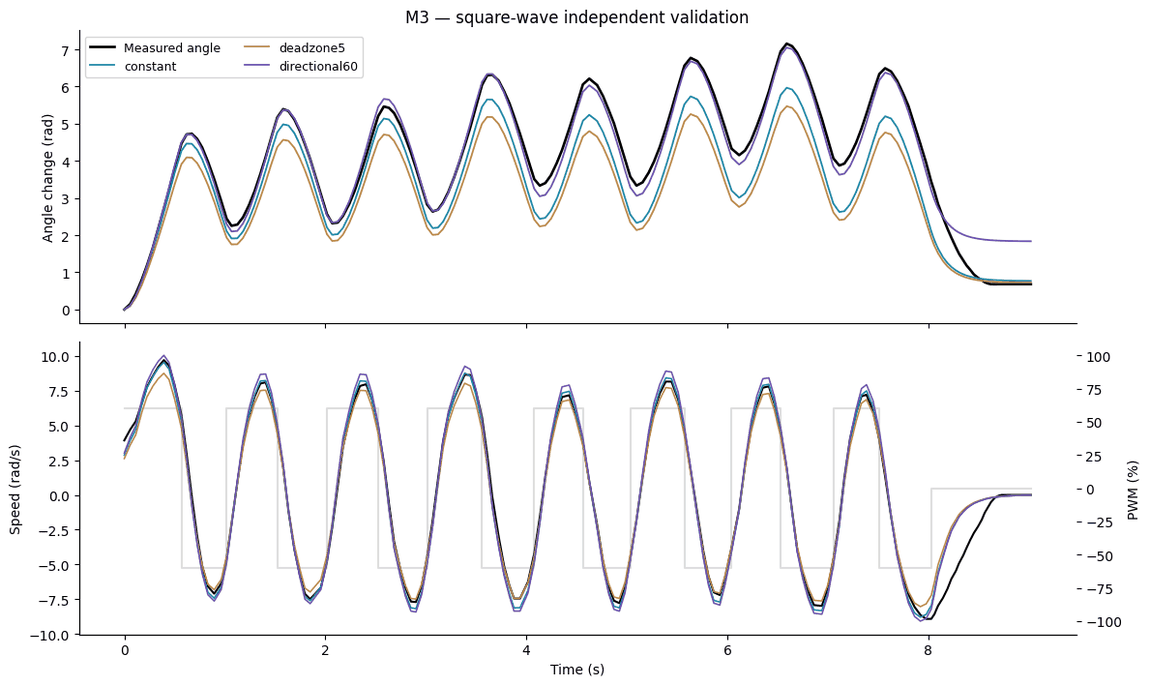

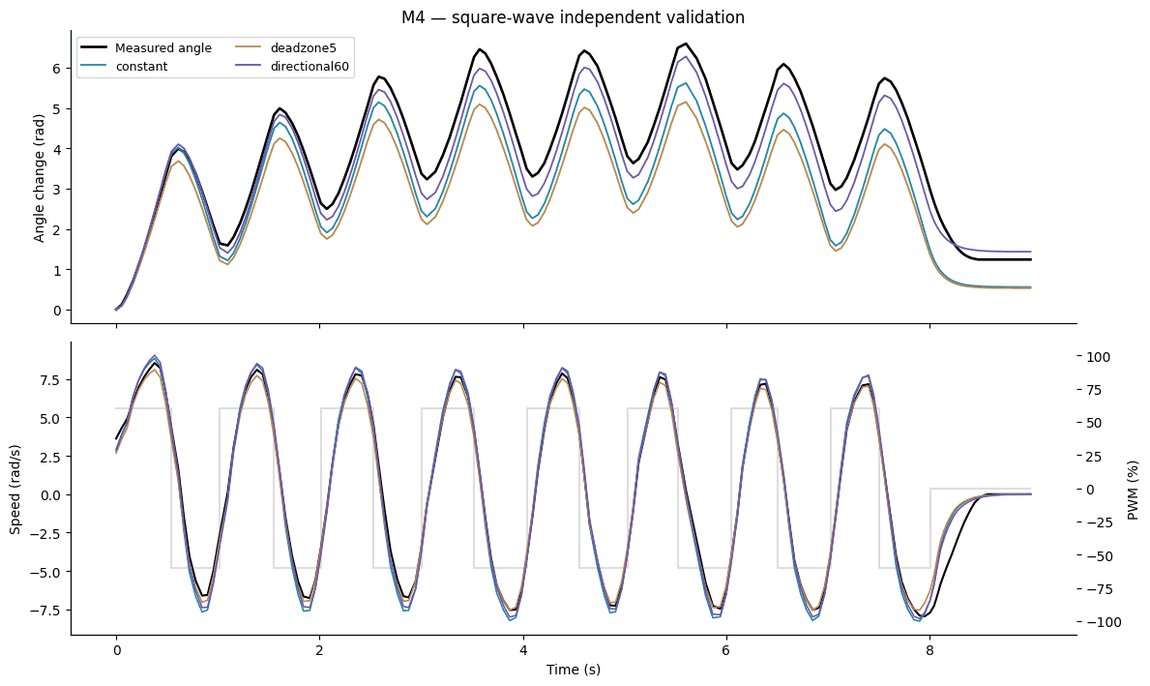

In [7]:
for m in MOTORS:
    d=sq_data[m];t=d['time'];th=d['angle'];pwm=d['PWM']
    pred=d['prediction']
    fig,ax=plt.subplots(2,1,figsize=(12,7.2),sharex=True)
    ax[0].plot(t,th,color='black',lw=1.9,label='Measured angle')
    for k,c in [('constant','#1e88a8'),('deadzone5','#bb8949'),('directional60','#6c54b0')]:
        ax[0].plot(t,pred[k][:,1],lw=1.3,color=c,label=k.replace('_',' '))
    ax[0].set(ylabel='Angle change (rad)',title=f'{m} — square-wave independent validation')
    ax[0].legend(fontsize=9,ncol=2)
    ax[1].plot(t,d['omega_smooth'],lw=1.5,color='black',label='Measured speed (5-point smooth)')
    for k,c in [('constant','#1e88a8'),('deadzone5','#bb8949'),('directional60','#6c54b0')]:
        ax[1].plot(t,smooth(pred[k][:,0],5),lw=1.15,color=c,label=k.replace('_',' '))
    ax[1].set(xlabel='Time (s)',ylabel='Speed (rad/s)')
    sec=ax[1].twinx();sec.step(t,pwm,color='gray',alpha=.26,where='post',label='PWM input')
    sec.set_ylabel('PWM (%)');sec.set_ylim(-110,110)
    fig.tight_layout();fig.savefig(FIGS/f'03_{m}_complex_angle_speed.png');plt.show()

## Measurement artifacts

Zero drift, coasting, sampling intervals, and directional differences.

In [8]:
artifact=[];coast_examples={};dt_all=[]
for m in MOTORS:
    for run in RUNS:
        a=raw_step[m,run]
        seg=segments(a)
        zero=seg[0][0]
        dt=np.diff(a[:,1])
        dt_all.append({'Motor':m,'Run':run,'N samples':len(a),'Mean interval (ms)':np.mean(dt),
                       'Median (ms)':np.median(dt),'Min (ms)':np.min(dt),'Max (ms)':np.max(dt),
                       'Std interval (ms)':np.std(dt)})
        cos=[]
        for k in range(1,len(seg)-1):
            z,p,_,_=seg[k]
            if p==0:continue
            nxt=seg[k+1][0]
            if len(nxt)<3:continue
            dtheta=np.deg2rad(nxt[-1,0]-nxt[0,0])
            cos.append((p,dtheta,nxt))
            if run==1 and p in (-60,60): coast_examples[m,p]=nxt
        ar=np.array([abs(x[1]) for x in cos])
        artifact.append({'Motor':m,'Run':run,
                         'Initial zero drift (degrees)':zero[-1,0]-zero[0,0],
                         'Initial zero duration (s)':(zero[-1,1]-zero[0,1])/1000,
                         'Mean |coast angle| (rad)':ar.mean(),
                         'Max |coast angle| (rad)':ar.max(),
                         'Coast after +60 (rad)':next(x[1] for x in cos if x[0]==60),
                         'Coast after -60 (rad)':next(x[1] for x in cos if x[0]==-60)})
print('Artifacts / coasting:')
display(pd.DataFrame(artifact).round(4))
print('Sampling (expected block timer 5 ms, actual file-writing interval is much larger):')
display(pd.DataFrame(dt_all).round(3))

Artifacts / coasting:


  Motor  Run  ...  Coast after +60 (rad)  Coast after -60 (rad)
0    M3    1  ...                 3.5256                -3.7001
1    M3    2  ...                 3.4034                -3.3510
2    M4    1  ...                 1.0821                -2.0420
3    M4    2  ...                 2.1118                -1.9897

[4 rows x 8 columns]

Sampling (expected block timer 5 ms, actual file-writing interval is much larger):


  Motor  Run  N samples  ...  Min (ms)  Max (ms)  Std interval (ms)
0    M3    1       1754  ...    29.502   126.633              7.283
1    M3    2       1708  ...    29.934    99.934              7.234
2    M4    1       1710  ...    30.149    90.433              6.647
3    M4    2       1764  ...    29.504   102.492              7.079

[4 rows x 8 columns]

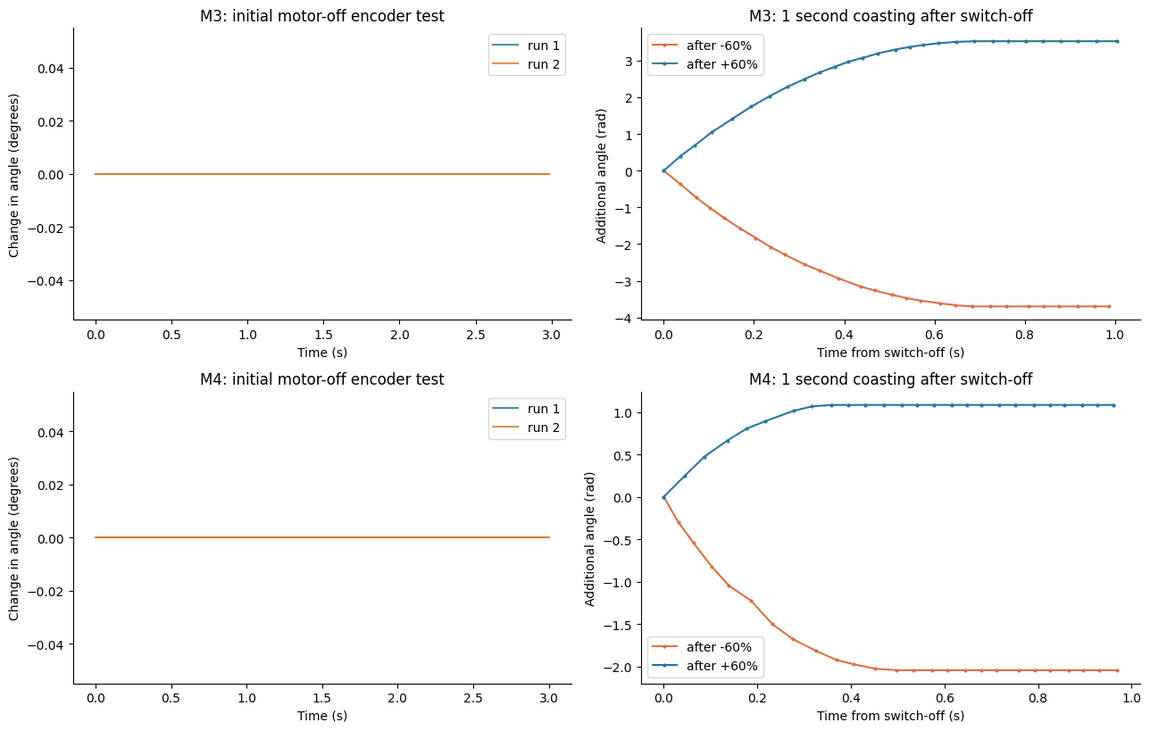

In [9]:
fig,axes=plt.subplots(2,2,figsize=(13,8.3))
for j,m in enumerate(MOTORS):
    for run in RUNS:
        a=raw_step[m,run];start=segments(a)[0][0]
        t=(start[:,1]-start[0,1])/1000
        axes[j,0].step(t,start[:,0]-start[0,0],where='post',label=f'run {run}',alpha=.8)
    axes[j,0].set(title=f'{m}: initial motor-off encoder test',xlabel='Time (s)',ylabel='Change in angle (degrees)')
    axes[j,0].legend()
    for p,col in [(-60,'#db7045'),(60,'#2378a2')]:
        z=coast_examples[m,p];tt=(z[:,1]-z[0,1])/1000
        axes[j,1].plot(tt,np.deg2rad(z[:,0]-z[0,0]),label=f'after {p:+d}%',color=col,marker='o',markersize=2)
    axes[j,1].set(title=f'{m}: 1 second coasting after switch-off',xlabel='Time from switch-off (s)',ylabel='Additional angle (rad)')
    axes[j,1].legend()
fig.tight_layout();fig.savefig(FIGS/'05_zero_drift_and_coasting.png');plt.show()

In [10]:
repeat=[];asym=[];noise=[]
for m in MOTORS:
    q=agg[agg.Motor==m]
    relative=100*q.omega_run_spread.to_numpy()/np.maximum(np.abs(q.omega_ss.to_numpy()),1e-9)
    tdiff=q.Tm_run_spread.to_numpy()
    repeat.append({'Motor':m,'Mean repeatability difference in |speed| (%)':np.mean(relative),
                   'Maximum repeat difference in |speed| (%)':np.max(relative),
                   'Mean absolute Tm difference (s)':np.mean(tdiff)})
    for p in (10,30,60,90):
        pp=q[q.PWM==p].iloc[0];nn=q[q.PWM==-p].iloc[0]
        asym.append({'Motor':m,'|PWM|':p,'Positive speed (rad/s)':pp.omega_ss,
                     'Negative |speed| (rad/s)':abs(nn.omega_ss),
                     'Speed directional gap (%)':100*abs(pp.omega_ss-abs(nn.omega_ss))/((pp.omega_ss+abs(nn.omega_ss))/2),
                     'Tm directional gap (%)':100*abs(pp.Tm-nn.Tm)/((pp.Tm+nn.Tm)/2)})
    d=sq_data[m];unsmoothed=np.gradient(d['angle'],d['time']);smoothed=d['omega_smooth']
    noise.append({'Motor':m,'Raw-vs-smoothed speed std (rad/s)':np.std(unsmoothed-smoothed),
                  'Integer-encoder step (deg)':1})
display(pd.DataFrame(asym)[['Motor','|PWM|','Speed directional gap (%)','Tm directional gap (%)']].round(2))

  Motor  |PWM|  Speed directional gap (%)  Tm directional gap (%)
0    M3     10                       1.58                    7.38
1    M3     30                       2.03                    8.48
2    M3     60                       0.96                    2.74
3    M3     90                       2.73                   15.04
4    M4     10                       0.96                    4.36
5    M4     30                       3.64                    3.47
6    M4     60                       4.26                    3.85
7    M4     90                       5.84                    2.26

### Additional checks

In [11]:
transition=[]
for m in MOTORS:
    d=sq_data[m]; t=d['time'];pwm=d['PWM'];omega=d['omega_smooth']
    idx=np.where((np.diff(np.sign(pwm))!=0)&(pwm[1:]!=0)&(pwm[:-1]!=0))[0]+1
    delays=[]
    for j in idx:
        j2=next((k for k in range(j,min(j+12,len(t))) if np.sign(omega[k])==np.sign(pwm[j])),None)
        if j2 is not None:delays.append(t[j2]-t[j])
    q=agg[agg.Motor==m]
    for p in (-1,1):
        w80=abs(float(q.loc[q.PWM==p*80,'omega_ss'].iloc[0]));w100=abs(float(q.loc[q.PWM==p*100,'omega_ss'].iloc[0]))
        transition.append({'Motor':m,'Direction':'forward' if p>0 else 'backward',
                 'Delta |speed| 80→100% (rad/s)':w100-w80,
                 'Mean reversal-to-correct-direction delay (s)':float(np.mean(delays)),
                 'Median delay (s)':float(np.median(delays)),
                 'Reversals observed':len(idx),'Delays resolved':len(delays)})
print('Reversals and high-PWM speed increments:')
display(pd.DataFrame(transition).round(3))

RESULTS=Path('results'); RESULTS.mkdir(exist_ok=True)
fit_rows.to_csv(RESULTS/'all_80_step_fits.csv',index=False)
agg.to_csv(RESULTS/'step_fits_averaged_by_pwm.csv',index=False)
summary.to_csv(RESULTS/'direction_calibration.csv',index=False)
metrics.to_csv(RESULTS/'square_wave_validation.csv',index=False)
pd.DataFrame(artifact).to_csv(RESULTS/'coasting_and_zero_drift.csv',index=False)
pd.DataFrame(dt_all).to_csv(RESULTS/'sampling_statistics.csv',index=False)
pd.DataFrame(transition).to_csv(RESULTS/'saturation_and_reversal_checks.csv',index=False)
print('Exported result tables to:',RESULTS.resolve())

Reversals and high-PWM speed increments:


  Motor Direction  ...  Reversals observed  Delays resolved
0    M3  backward  ...                  15               15
1    M3   forward  ...                  15               15
2    M4  backward  ...                  15               15
3    M4   forward  ...                  15               15

[4 rows x 7 columns]

Exported result tables to: /tmp/run_assignment_ookdp6s_/results
